# 03 — Scenes: spectra, hosts and backgrounds

The SNR of a source depends on what its spectrum does inside the filter, on the galaxy it sits in,
and on the sky behind it. `get_scene` builds all three.

In this notebook:
1. stellar templates and how the magnitude is normalized,
2. parametric spectra: flat, blackbody, power law, emission lines; a spectrum from a file,
3. the background,
4. a transient on a Sersic host, and on a real galaxy at a redshift.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import wcc_etc
from wcc_etc import Simulation, get_scene

wcc_etc.set_wcc_style()

***
## 1. Stellar templates

The source name is a Pickles spectral type (`O5V` … `M5V`, giants `K3III`, …). At the same r
magnitude the SNR in r hardly depends on the type; in u and z it does, because the template sets
the colour.

In [2]:
types = ["O5V", "A0V", "F5V", "G2V", "K5V", "M5V", "K3III"]
filters = ["zwo:u", "zwo:r", "zwo:z"]
print(f"{'type':6s}" + "".join(f"{f:>9s}" for f in filters) + "   (SNR in 60 s at r = 20 AB)")
for sp in types:
    scene = get_scene(sp, mag=20, bandpass="sdss_r", magsys="abmag")
    snr = [Simulation.from_sensorfilter(f, scene).get_image_snr(60, warn=False)["snr"] for f in filters]
    print(f"{sp:6s}" + "".join(f"{s:9.1f}" for s in snr))

type      zwo:u    zwo:r    zwo:z   (SNR in 60 s at r = 20 AB)


[wcc_etc] note: even n_pixels is rounded up by 1 to center the PSF peak (shown once).


O5V        94.8    143.9     29.2


A0V        47.6    143.0     36.3


F5V        32.0    141.2     44.3


G2V        23.2    140.4     48.6


K5V         5.7    138.3     59.8


M5V         2.6    124.5    149.9


K3III       5.9    138.2     57.5


**Normalization.** `mag` is interpreted in `bandpass` and `magsys`. Leaving them out means
Johnson V in Vega magnitudes, whatever the observing filter. A G2V star at V = 20 (Vega) is 0.2
mag brighter in r than an r = 20 (AB) one; for an M dwarf the difference is more than a magnitude.

In [3]:
for sp in ("G2V", "M5V"):
    s_v = Simulation.from_sensorfilter("zwo:r", get_scene(sp, mag=20))                                   # V = 20, Vega (the default)
    s_r = Simulation.from_sensorfilter("zwo:r", get_scene(sp, mag=20, bandpass="sdss_r", magsys="abmag"))
    print(f"{sp}: SNR in r, 60 s: {s_v.get_image_snr(60, warn=False)['snr']:6.1f} at V = 20 (Vega), "
          f"{s_r.get_image_snr(60, warn=False)['snr']:6.1f} at r = 20 (AB)")

G2V: SNR in r, 60 s:  152.1 at V = 20 (Vega),  140.4 at r = 20 (AB)


M5V: SNR in r, 60 s:  186.6 at V = 20 (Vega),  124.5 at r = 20 (AB)


***
## 2. Parametric spectra, and your own

`"flat"` ($F_\nu$ = constant, i.e. AB colours of zero), `"blackbody"` with `teff`, `"powerlaw"`
with `alpha` ($F_\lambda \propto \lambda^\alpha$), and `"emission"` with a list of lines
(`mag=None`: the line fluxes are absolute). `get_spectrum(as_array=True)` returns the normalized
spectrum for plotting.

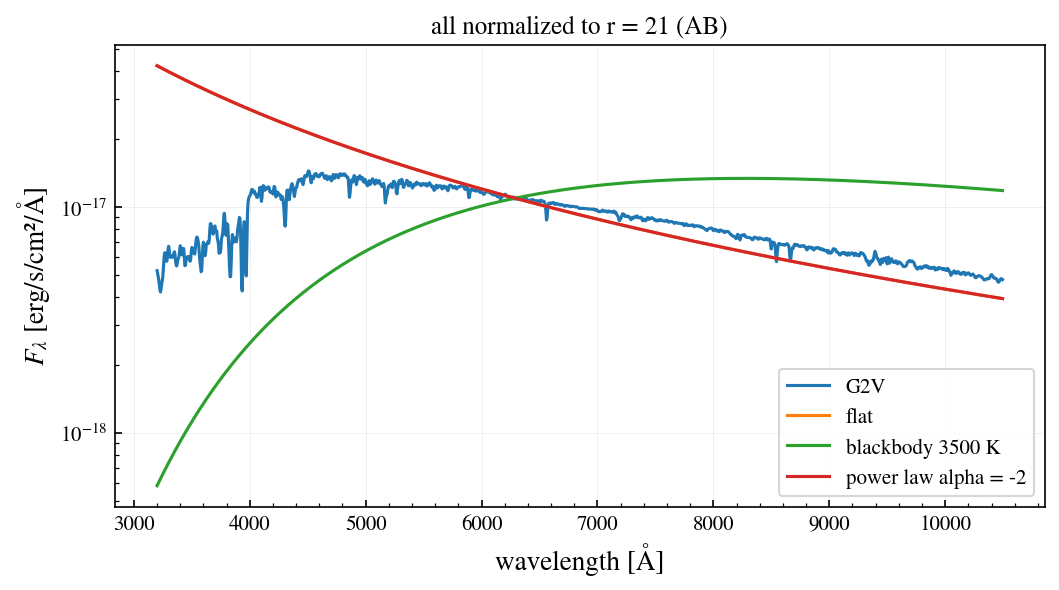

G2V                    SNR in 60 s: u  11.7, z  27.5


flat                   SNR in 60 s: u  32.9, z  24.5


blackbody 3500 K       SNR in 60 s: u   3.5, z  43.4
power law alpha = -2   SNR in 60 s: u  32.9, z  24.5


In [4]:
import astropy.units as u

scenes = {
    "G2V": get_scene("G2V", mag=21, bandpass="sdss_r", magsys="abmag"),
    "flat": get_scene("flat", mag=21, bandpass="sdss_r", magsys="abmag"),
    "blackbody 3500 K": get_scene("blackbody", teff=3500, mag=21, bandpass="sdss_r", magsys="abmag"),
    "power law alpha = -2": get_scene("powerlaw", alpha=-2, mag=21, bandpass="sdss_r", magsys="abmag"),
}
w = np.arange(3200, 10500, 5) * u.AA
fig, ax = plt.subplots(figsize=(8, 4))
for name, sc in scenes.items():
    wave, flux = sc.source.get_spectrum(as_array=True, wave=w, flux_unit="flam")
    ax.plot(wave, flux, label=name)
ax.set(xlabel="wavelength [Å]", ylabel="$F_\lambda$ [erg/s/cm²/Å]", yscale="log", title="all normalized to r = 21 (AB)")
ax.legend()
plt.show()

for name, sc in scenes.items():
    print(f"{name:22s} SNR in 60 s: u {Simulation.from_sensorfilter('zwo:u', sc).get_image_snr(60, warn=False)['snr']:5.1f}, "
          f"z {Simulation.from_sensorfilter('zwo:z', sc).get_image_snr(60, warn=False)['snr']:5.1f}")

The power law with $\alpha = -2$ gives the same numbers as `"flat"`: $F_\lambda \propto \lambda^{-2}$ is
constant in $F_\nu$, which is what "flat" means in AB magnitudes.

An emission-line source: a point source with a 4 Å wide line of $10^{-15}$ erg/s/cm² at H-alpha,
with no continuum. The narrow H-alpha filter and the broad r filter collect the same line photons
but very different amounts of background and continuum (exercise 4).

In [5]:
import warnings
warnings.filterwarnings("ignore", message="spectrum")      # the line spectrum does not cover the whole filter: expected

line = [{"wave": 6563.0, "flux": 1e-15, "fwhm": 4}]
scene_line = get_scene("emission", mag=None, lines=line)
for f in ("zwo:halpha2", "zwo:halpha20", "zwo:r"):
    print(f"{f:13s}: line SNR in 300 s = {Simulation.from_sensorfilter(f, scene_line).get_image_snr(300, warn=False)['snr']:5.1f}")

zwo:halpha2  : line SNR in 300 s =  42.6
zwo:halpha20 : line SNR in 300 s =  42.4


zwo:r        : line SNR in 300 s =  41.6


> 🤖 **Ask Jupyter AI:** *I have my object's spectrum in a two-column text file (wavelength in Å, flux in erg/s/cm²/Å). Show me how to load it with wcc_etc.get_scene_from_file, normalize it to r = 21 AB, and compute the SNR in 300 s in zwo:r.*
>
> `get_scene_from_file(path, mag=21, bandpass='sdss_r', magsys='abmag')` is the call; the agent should find the column and unit arguments in the docstring.

***
## 3. The background

The default background is zodiacal light at V = 22.5 mag/arcsec² (Vega). `background_prop`
overrides it; the Lazuli L3 requirement value is 22.1. It matters only for faint sources.

In [6]:
for m_src in (20, 24, 27):
    row = []
    for m_sky in (22.5, 22.1, 21.0):
        sc = get_scene("G2V", mag=m_src, bandpass="sdss_r", magsys="abmag", background="zodi", background_prop={"mag": m_sky})
        row.append(Simulation.from_sensorfilter("zwo:r", sc).get_image_snr(300, warn=False)["snr"])
    print(f"r = {m_src}: SNR in 300 s = {row[0]:6.1f} (sky 22.5), {row[1]:6.1f} (22.1), {row[2]:6.1f} (21.0 mag/arcsec²)")

r = 20: SNR in 300 s =  317.1 (sky 22.5),  317.0 (22.1),  316.1 (21.0 mag/arcsec²)


r = 24: SNR in 300 s =   43.9 (sky 22.5),   43.3 (22.1),   40.0 (21.0 mag/arcsec²)


r = 27: SNR in 300 s =    5.1 (sky 22.5),    4.9 (22.1),    3.9 (21.0 mag/arcsec²)


***
## 4. A transient on a host galaxy

`host` adds a second scene element. A Sersic profile is set with `host_prop`: total magnitude,
`r_eff` (arcsec), index `n`, and the offset `dx`, `dy` (arcsec) of the source from the nucleus.
The host adds photon noise under the transient and can saturate the nucleus.

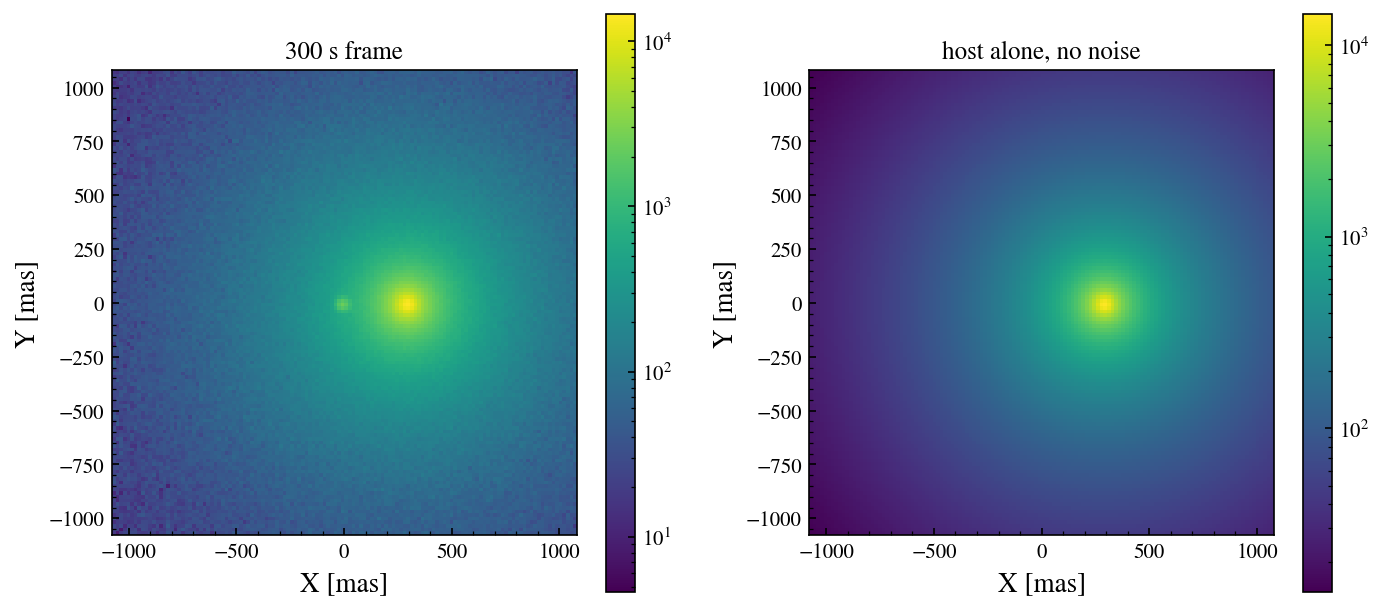

transient r = 22 at 0.3" from an r = 16 nucleus: SNR 71.1 in 300 s, saturated: False


In [7]:
scene = get_scene("G5V", mag=22, bandpass="sdss_r", magsys="abmag",
                  host="G5V", host_prop={"mag": 16, "profile": "sersic", "r_eff": 0.5, "n": 4, "dx": 0.3,
                                         "bandpass": "sdss_r", "magsys": "abmag"})
sim = Simulation.from_sensorfilter("zwo:r", scene)
fig, axes = sim.plot_host(300)
plt.show()
r = sim.get_image_snr(300, warn=False)
print(f"transient r = 22 at 0.3\" from an r = 16 nucleus: SNR {r['snr']:.1f} in 300 s, saturated: {r['saturated']}")

> ✏️ **Before you run the next cell:** moving the transient from 0.3" to 3" from the nucleus: does the SNR go up by 10 %, 50 % or a factor of 3? Write your guess down (or put it in the room poll), then run.

In [8]:
blank = Simulation.from_sensorfilter("zwo:r", get_scene("G5V", mag=22, bandpass="sdss_r", magsys="abmag"))
print(f"{'offset':>8} {'SNR':>6}")
for dx in (0.0, 0.3, 1.0, 3.0):
    sim.update(host__dx=dx)
    r = sim.get_image_snr(300, n_reads=3, warn=False)
    print(f"{dx:7.1f}\" {r['snr']:6.1f}" + ("  (saturated)" if r["saturated"] else ""))
print(f"{'no host':>8} {blank.get_image_snr(300, n_reads=3, warn=False)['snr']:6.1f}")

  offset    SNR


    0.0"   24.3


    0.3"   70.3


    1.0"  110.6
    3.0"  119.3
 no host  119.9


**A real galaxy at a redshift.** `host="ngc0628"` takes the r-band image and spectrum of NGC 628
(76 NGC galaxies are available). One `redshift` moves source and host together: a supernova with
absolute magnitude `magabs` is placed through the distance modulus, and the galaxy keeps its physical
size, so it shrinks on the sky with distance. `"hsiao07"` is a SN Ia template.

z = 0.05: SN Ia r = 17.40 mag(AB), SNR 1065.4 in 300 s (8 reads)


z = 0.20: SN Ia r = 20.44 mag(AB), SNR  259.7 in 300 s (1 reads)


z = 0.50: SN Ia r = 22.33 mag(AB), SNR  104.2 in 300 s (1 reads)


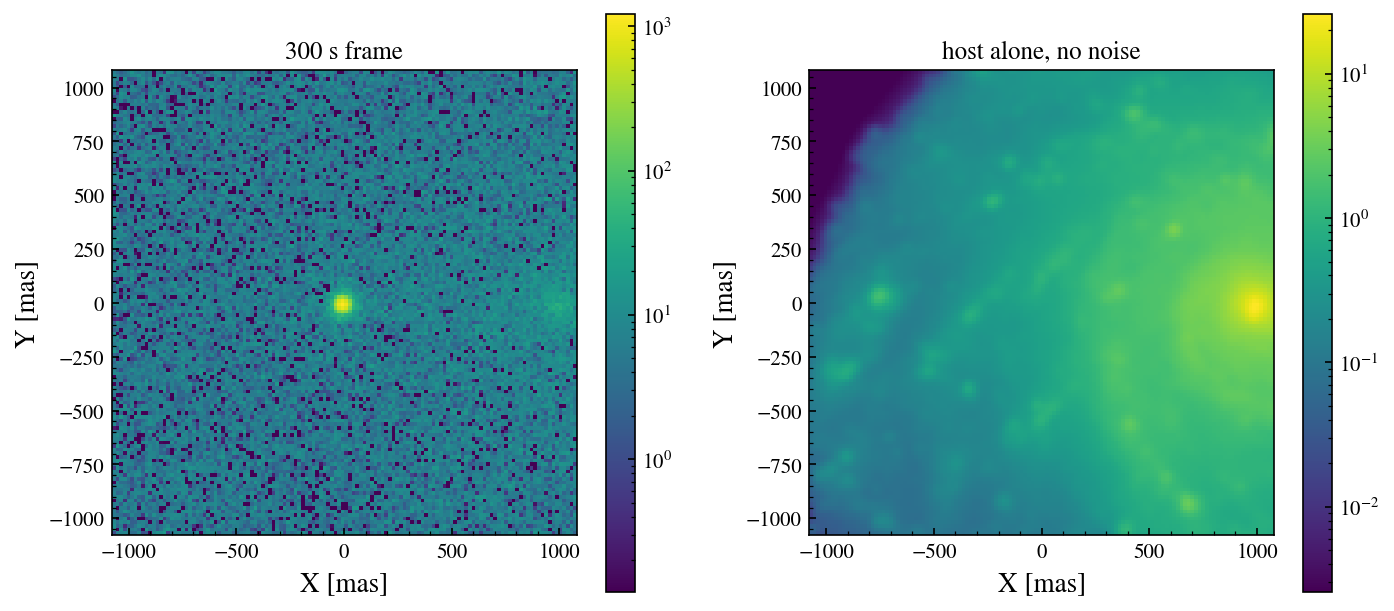

In [9]:
for z in (0.05, 0.2, 0.5):
    scene = get_scene("hsiao07", mag=None, magabs=-19.3, redshift=z, bandpass="sdss_r", magsys="abmag",
                      host="ngc0628", host_prop={"dx": 1.0})
    sim = Simulation.from_sensorfilter("zwo:r", scene)
    n = 1
    r = sim.get_image_snr(300, warn=False)
    while r["saturated"] and n < 100:
        n *= 2
        r = sim.get_image_snr(300, n_reads=n, warn=False)
    print(f"z = {z:4.2f}: SN Ia r = {sim.scene.source.mag:5.2f}, SNR {r['snr']:6.1f} in 300 s ({n} reads)")

fig, axes = sim.plot_host(300)
plt.show()

***
## Summary

```python
get_scene("K5V", mag=20, bandpass="sdss_r", magsys="abmag")            # a template; always give bandpass + magsys
get_scene("blackbody", teff=3500, mag=21, ...)                          # "flat", "powerlaw" (alpha), "emission" (lines, mag=None)
get_scene_from_file("spec.txt", mag=21, ...)                            # your own spectrum
get_scene(..., background_prop={"mag": 22.1})                           # the sky
get_scene("G5V", mag=22, ..., host="G5V", host_prop={"mag": 16, "profile": "sersic", "r_eff": 0.5, "n": 4, "dx": 0.3})
get_scene("hsiao07", mag=None, magabs=-19.3, redshift=0.2, ..., host="ngc0628")
sim.update(host__dx=1.0)                                                # host__ and source__ prefixes
```

Next: [04 — PSF, apertures and images](04_psf_apertures_images.ipynb).